<a href="https://colab.research.google.com/github/amaliaciungulet/ML-Seminar_CiunguletAmalia/blob/main/tema_laborator_3_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [ ]:
# TODO 1.1 — procentul de valori lipsă pe coloană
valori_lipsa=(df.isnull().sum() / len(df))*100
print("procentul de valori lipsă pe coloana:")
print(valori_lipsa.sort_values(ascending=False))

# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă

coloane_eliminate = valori_lipsa[valori_lipsa > 50].index
print(f"\nColoanele care vor fi eliminate: {list(coloane_eliminate)}")

df = df.drop(columns=coloane_eliminate)


procentul de valori lipsă pe coloana:
deck        77.216611
age         19.865320
embarked     0.224467
sex          0.000000
pclass       0.000000
survived     0.000000
fare         0.000000
dtype: float64

Coloanele care vor fi eliminate: ['deck']


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [ ]:
# TODO 2.1 — imputare age (mediană) și embarked (mod)
age_inainte = df['age'].copy() #copia inainte de imputare

mediana_age=df['age'].median()
df['age']=df['age'].fillna(mediana_age)

mod_embarked=df['embarked'].mode()[0]
df['embarked']=df['embarked'].fillna(mod_embarked)

# TODO 2.2 — verificare + comparație deviație standard
print("valori lipsa ramase in dataset:")
print(df.isnull().sum())

print(f"\ndeviatia standard a varstei inainte de imputare: {age_inainte.std():.4f}")
print(f"deviatia standard a varstei dupa imputare: {df['age'].std():.4f}")


valori lipsa ramase in dataset:
survived    0
pclass      0
sex         0
age         0
fare        0
embarked    0
dtype: int64

deviatia standard a varstei inainte de imputare: 14.5265
deviatia standard a varstei dupa imputare: 13.0197


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

skewness pentru variabila  'fare': 4.7873
skewness dupa transformarea logaritmica ('log_fare'): 0.3949


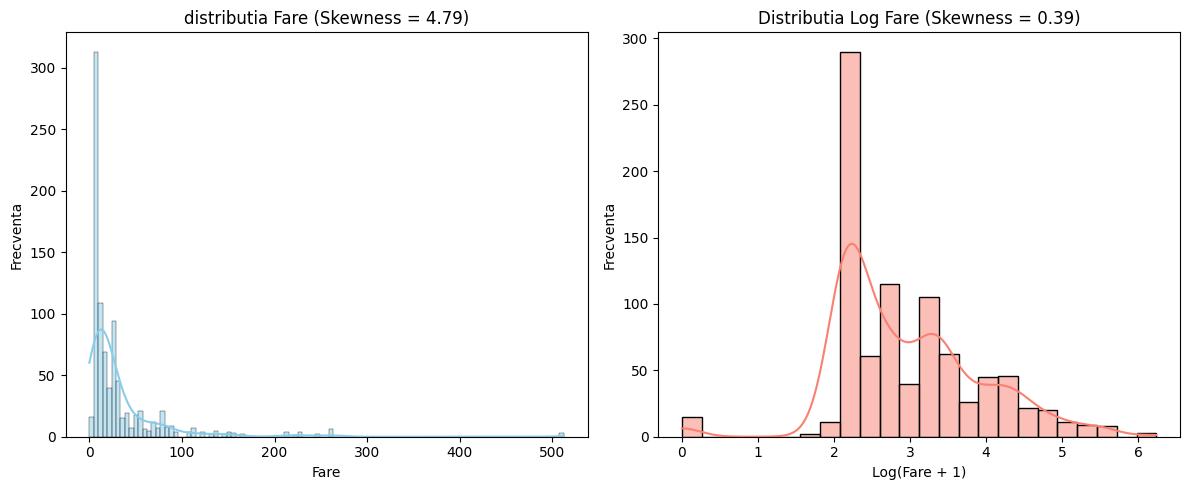

In [ ]:
# TODO 3.1 — skewness fare


# TODO 3.2 — coloana log_fare + skewness


# TODO 3.3 — două histograme

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [ ]:
# TODO 4.1 — limite IQR + număr de outlieri


# TODO 4.2 — fare_capped (clip) + maxim înainte/după


limita inferioara: -26.7240
limita superioara: 65.6344
numarr de outlieri detectati pentru 'fare': 116

Valoarea maxima a 'fare' inainte de limitare: 512.3292
Valoarea maxima a 'fare' după limitare (fare_capped): 65.6344


In [ ]:
# TODO 4.1 — limite IQR + număr de outlieri

# TODO 4.1 — limite IQR + număr de outlieri


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [ ]:
# TODO 5.1 — One-Hot Encoding pentru sex și embarked
df=pd.get_dummies(df, columns=['sex', 'embarked'], drop_first=True, dtype=int)
print("Coloane dupa One-Hot Encoding:")
print(df.columns.tolist())
# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std
scaler=StandardScaler()
df[['age', 'fare_capped']]=scaler.fit_transform(df[['age', 'fare_capped']])

print("\nVerificare dupa scalare (StandardScaler):")
print(f"Media pentru 'age': {df['age'].mean():.4f}")
print(f"Deviatia standard pentru 'age': {df['age'].std():.4f}")
print(f"Media pentru 'fare_capped': {df['fare_capped'].mean():.4f}")
print(f"Deviatia standard pentru 'fare_capped': {df['fare_capped'].std():.4f}")
display(df.head())

Coloane dupa One-Hot Encoding:
['survived', 'pclass', 'age', 'fare', 'log_fare', 'fare_capped', 'sex_male', 'embarked_Q', 'embarked_S']

Verificare dupa scalare (StandardScaler):
Media pentru 'age': 0.0000
Deviatia standard pentru 'age': 1.0006
Media pentru 'fare_capped': 0.0000
Deviatia standard pentru 'fare_capped': 1.0006


,survived,pclass,age,fare,log_fare,fare_capped,sex_male,embarked_Q,embarked_S
0,0,3,-0.565736,7.2500,2.110213,-0.820552,1,0,1
1,1,1,0.663861,71.2833,4.280593,2.031623,0,0,0
2,1,3,-0.258337,7.9250,2.188856,-0.787578,0,0,1
3,1,1,0.433312,53.1000,3.990834,1.419297,0,0,1
4,0,3,0.433312,8.0500,2.202765,-0.781471,1,0,1


## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*

Am imputat 'age' pentru ca are putine valori lipsa in comparatie cu variabila 'deck'. Age este o variabila importanta in analiza, iar deck, prin valorile lui lipsa, ar fi distorsionat analiza.